# Walkthrough: the parallel MRI pipeline, step by step

This notebook calls the code in `src/mri_pipeline/` and runs in fast mode (Hessian sigmas 1-9).

- By default it uses a small **synthetic** image set, so it runs anywhere (CI included) without the MRI data.
- With `MRI_USE_REAL_DATA=1` it uses the real images in `data/brain_tumor_dataset/` (see the README for how to get them).

Anything timed or trained here is a **quick demo** on the subset size printed next to it. The benchmark numbers in the README come from `results/`, and the last section only reads them.
No MRI images are displayed; the filter example uses a synthetic image.

In [1]:
import os
import tempfile
from pathlib import Path

import numpy as np

from mri_pipeline import io, parallel
from mri_pipeline.features import image_features, rescale_direct_cast, rescale_to_uint8
from mri_pipeline.filters import FILTER_NAMES, apply_filters
from mri_pipeline.synthetic import make_dataset

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REAL = os.environ.get("MRI_USE_REAL_DATA") == "1"
if REAL:
    DATA = ROOT / "data" / "brain_tumor_dataset"
    print("data: the real MRI dataset")
else:
    DATA = Path(tempfile.mkdtemp()) / "brain_tumor_dataset"
    make_dataset(DATA, n_per_class=8, seed=0)
    print("data: a synthetic set (8 images per class + 1 exact duplicate)")

data: the real MRI dataset


## 1. Load every image, whatever the extension case

A pattern like `glob('*.jpg')` would skip `.JPG`, `.jpeg` and `.png` files. The loader checks the lower-cased extension and hashes every file, so exact duplicates can be grouped later.

In [2]:
records = io.list_images(DATA)
print("images found:", len(records))
print("by class and extension:", io.count_by_class_and_extension(records))
groups = io.duplicate_groups([r.sha256 for r in records])
print("exact duplicate files:", len(records) - len(set(groups.tolist())))

images found: 253
by class and extension: {'no': {'.jpeg': 6, '.jpg': 85, '.JPG': 6, '.png': 1}, 'yes': {'.jpg': 86, '.JPG': 68, '.png': 1}}
exact duplicate files: 25


## 2. The six filters on one image

Shown on a synthetic image, so no MRI scan is reproduced here.

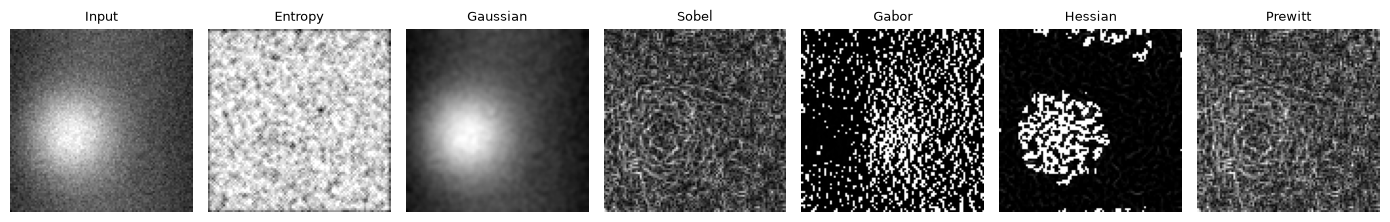

In [3]:
import matplotlib.pyplot as plt

from mri_pipeline.synthetic import synthetic_image

demo = synthetic_image(np.random.default_rng(0), (96, 96), tumour=True)
filtered = apply_filters(demo, "fast")
fig, axes = plt.subplots(1, len(filtered), figsize=(14, 2.4))
for ax, (name, img) in zip(axes, filtered.items(), strict=True):
    ax.imshow(img, cmap="gray")
    ax.set_title(name, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Rescaling filter outputs before the GLCM

A direct cast `(image * 255).astype(np.uint8)` inverts uint8 images (v becomes 256 - v) and wraps float outputs above 1. Min-max scaling each output to 0-255 avoids both. The direct cast is kept only as an ablation in the ML results.

In [4]:
for name in ("Input", "Entropy", "Sobel"):
    out = filtered[name]
    direct = rescale_direct_cast(out)
    minmax = rescale_to_uint8(out)
    print(
        f"{name:8s} {str(out.dtype):8s} [{out.min():.3g}, {out.max():.3g}]"
        f" | direct cast -> [{direct.min()}, {direct.max()}]"
        f"  min-max -> [{minmax.min()}, {minmax.max()}]"
    )
value = rescale_direct_cast(np.array([200], dtype=np.uint8))[0]
print("uint8 value 200 after a direct cast ->", value)

Input    uint8    [15, 255] | direct cast -> [1, 241]  min-max -> [0, 255]
Entropy  float64  [2.35, 3.7] | direct cast -> [2, 253]  min-max -> [0, 255]
Sobel    float64  [1.39e-17, 0.138] | direct cast -> [0, 35]  min-max -> [0, 255]
uint8 value 200 after a direct cast -> 56


## 4. Profile first

cProfile on 2 images shows which stage to parallelise. It runs through the CLI in a separate Python process, because cProfile's per-function times were not reliable inside a Jupyter kernel when I tested it. The 5-image profiles in `results/` are the reference numbers.

In [5]:
import csv
import subprocess
import sys

images = io.load_images(records)
out_dir = Path(tempfile.mkdtemp())
subprocess.run(
    [
        sys.executable,
        "-m",
        "mri_pipeline",
        "profile",
        "--fast",
        "--images",
        "2",
        "--data-dir",
        str(DATA),
        "--out-dir",
        str(out_dir),
    ],
    check=True,
    capture_output=True,
)
print("quick demo: cProfile of the fast pipeline on 2 images")
with open(out_dir / "profile_fast.csv", encoding="utf-8") as handle:
    for row in csv.DictReader(handle):
        print(f"  {row['stage']:48s} {float(row['share_pct']):5.1f} %")

quick demo: cProfile of the fast pipeline on 2 images
  Entropy                                            9.9 %
  Gaussian                                           0.2 %
  Sobel                                              0.8 %
  Gabor                                              0.7 %
  Hessian                                           63.3 %
  Prewitt                                            0.4 %
  GLCM (7 images x 24 features)                     24.6 %
  Other (loop, dict building, profiler overhead)     0.1 %
  Total                                            100.0 %


## 5. Parallel equals sequential

Each image is independent, so the pool works at the image level. The worker functions live in `src/`, so this also works with the `spawn` start method (Windows, macOS).

In [6]:
import functools

demo_images = images[:24]
task = functools.partial(apply_filters, mode="fast")
seq = parallel.timed_run(task, demo_images, strategy="sequential")
par = parallel.timed_run(task, demo_images, strategy="map", processes=2)
same = all(
    np.array_equal(a[k], b[k])
    for a, b in zip(seq.results, par.results, strict=True)
    for k in FILTER_NAMES
)
print(f"quick demo on {len(demo_images)} images, this machine, 1 run:")
print(f"  sequential {seq.seconds:.2f} s, Pool.map with 2 processes {par.seconds:.2f} s")
print(f"identical outputs: {same}")

quick demo on 24 images, this machine, 1 run:
  sequential 8.21 s, Pool.map with 2 processes 4.18 s
identical outputs: True


## 6. Cross-validation grouped by file hash

Identical files share a group, so a copy can never be in the training fold while another copy is in the test fold.

In [7]:
from mri_pipeline.train import cross_validate, leaked_groups, make_splits

y = np.array([r.label for r in records])
feats = parallel.run(functools.partial(image_features, mode="fast"), images)
X = np.stack([f["glcm_minmax"] for f in feats])
print(
    "groups shared between train and test, grouped CV:",
    leaked_groups(make_splits(y, groups, seed=0, n_splits=3), groups),
)
rows = cross_validate(X, y, groups, "logreg", seed=0, n_splits=3)
print(
    f"quick demo: LogReg on GLCM features, 3-fold grouped CV, seed 0, {len(images)} images;"
    " fold accuracies:",
    [round(r["accuracy"], 2) for r in rows],
)
print("(the full evaluation, 5 folds x 3 seeds and all models, is in results/ml_cv_summary.csv)")

groups shared between train and test, grouped CV: 0
quick demo: LogReg on GLCM features, 3-fold grouped CV, seed 0, 253 images; fold accuracies: [0.68, 0.79, 0.75]
(the full evaluation, 5 folds x 3 seeds and all models, is in results/ml_cv_summary.csv)


## 7. The benchmark results (read from `results/`, not recomputed)

In [8]:
from IPython.display import Markdown, display

from mri_pipeline.report import render_all

tables = render_all(ROOT / "results")
for name in ("profile_full", "scaling", "strategies", "ml"):
    if name in tables:
        display(Markdown(f"**{name}**\n\n" + tables[name]))

**profile_full**

Sequential pipeline, 5 images, full mode, cProfile cumulative time (`results/profile_full.csv`)

| Stage | Total (s) | Per image (s) | Share |
|---|---:|---:|---:|
| Entropy | 0.26 | 0.05 | 0.1 % |
| Gaussian | 0.01 | 0.00 | 0.0 % |
| Sobel | 0.02 | 0.00 | 0.0 % |
| Gabor | 0.03 | 0.01 | 0.0 % |
| Hessian | 171.73 | 34.35 | 99.1 % |
| Prewitt | 0.02 | 0.00 | 0.0 % |
| GLCM (7 images x 24 features) | 1.27 | 0.25 | 0.7 % |
| Other (loop, dict building, profiler overhead) | 0.00 | 0.00 | 0.0 % |
| **Total** | 173.33 | 34.67 | 100.0 % |

**scaling**

Task `filters`: 40 images, fast mode, native sizes, largest image = 18.2 % of all pixels, 3 run(s) each, 4 cores (Intel(R) Xeon(R) Processor @ 2.80GHz), start method `fork` (`results/scaling_summary.csv`)

| Configuration | Processes | Time (s), mean +/- sd | Speedup | Efficiency |
|---|---:|---:|---:|---:|
| Sequential loop (no pool) | 1 | 42.46 +/- 0.88 | 1.00x | 1.00 |
| Pool.map | 1 | 44.93 +/- 2.06 | 0.95x +/- 0.04 | 0.95 |
| Pool.map | 2 | 23.62 +/- 1.02 | 1.80x +/- 0.08 | 0.90 |
| Pool.map | 3 | 20.78 +/- 1.45 | 2.05x +/- 0.14 | 0.68 |
| Pool.map | 4 | 18.13 +/- 0.59 | 2.34x +/- 0.08 | 0.59 |

**strategies**

| Strategy | Processes | Chunk size used | Time (s), mean +/- sd | Speedup |
|---|---:|---:|---:|---:|
| Pool.map, chunksize auto | 4 | 3 | 17.83 +/- 0.27 | 2.38x |
| Pool.map, chunksize 1 | 4 | 1 | 14.72 +/- 0.08 | 2.88x |
| imap_unordered, chunksize 1 | 4 | 1 | 14.93 +/- 0.14 | 2.84x |
| imap_unordered, chunksize auto | 4 | 3 | 17.95 +/- 0.27 | 2.37x |

**ml**

253 images, 5-fold stratified CV grouped by file hash, seeds 0, 1, 2, mean +/- sd over 15 folds (`results/ml_cv_summary.csv`)

| Features | Model | Accuracy | Macro F1 | Tumour recall |
|---|---|---:|---:|---:|
| none | Majority class | 0.613 +/- 0.006 | 0.380 +/- 0.002 | 1.000 +/- 0.000 |
| raw pixels 64x64 | LogReg | 0.757 +/- 0.041 | 0.741 +/- 0.042 | 0.817 +/- 0.087 |
| raw pixels 64x64 | SVM (RBF) | 0.803 +/- 0.056 | 0.781 +/- 0.060 | 0.914 +/- 0.079 |
| raw pixels 64x64 | Random forest | 0.799 +/- 0.056 | 0.782 +/- 0.062 | 0.882 +/- 0.057 |
| GLCM, min-max rescale | LogReg | 0.747 +/- 0.058 | 0.722 +/- 0.067 | 0.845 +/- 0.057 |
| GLCM, min-max rescale | SVM (RBF) | 0.737 +/- 0.063 | 0.707 +/- 0.073 | 0.850 +/- 0.072 |
| GLCM, min-max rescale | Random forest | 0.752 +/- 0.070 | 0.731 +/- 0.075 | 0.834 +/- 0.094 |
| GLCM, direct uint8 cast (ablation) | LogReg | 0.759 +/- 0.062 | 0.733 +/- 0.067 | 0.865 +/- 0.088 |
| GLCM, direct uint8 cast (ablation) | SVM (RBF) | 0.717 +/- 0.068 | 0.684 +/- 0.081 | 0.837 +/- 0.075 |
| GLCM, direct uint8 cast (ablation) | Random forest | 0.721 +/- 0.058 | 0.691 +/- 0.063 | 0.834 +/- 0.081 |